<a href="https://colab.research.google.com/github/natacherchum/Descriptive_Statistics/blob/main/descriptive_stat_visualisations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = (
    "https://raw.githubusercontent.com/"
    "natacherchum/Descriptive_Statistics/"
    "refs/heads/main/descriptive_statistics_example1.csv"
)

df = pd.read_csv(url)

display(df)

,height_cm,weight_kg,activity_minutes
0,165.2,62.4,30.0
1,172.5,74.1,45.0
2,168.0,68.5,30.0
3,181.3,85.2,60.0
4,159.8,54.6,20.0
5,175.6,78.3,45.0
6,170.4,NaN,30.0
7,163.7,59.8,15.0
8,178.9,82.7,60.0
9,166.5,64.2,30.0


In [6]:
activity = df["activity_minutes"].dropna()

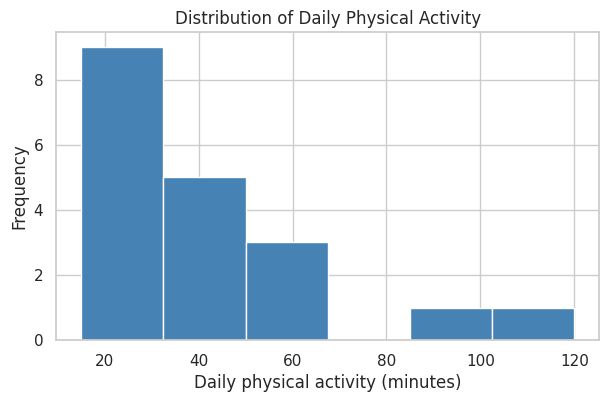

In [7]:
plt.figure(figsize=(7, 4))

plt.hist(
    activity,
    bins=6,
    color="steelblue",
    edgecolor="white",
)

plt.title("Distribution of Daily Physical Activity")
plt.xlabel("Daily physical activity (minutes)")
plt.ylabel("Frequency")

plt.show()

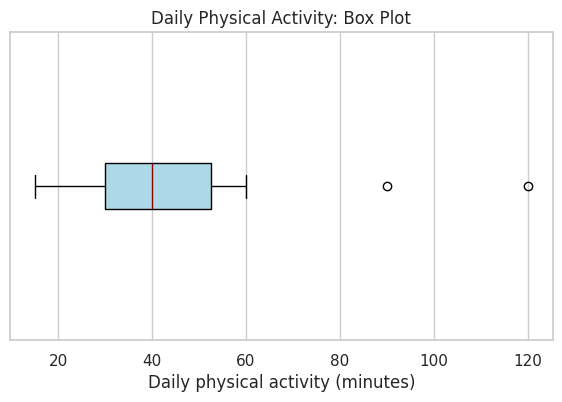

In [8]:
plt.figure(figsize=(7, 4))

plt.boxplot(
    activity,
    vert=False,
    patch_artist=True,
    boxprops={"facecolor": "lightblue"},
    medianprops={"color": "darkred"},
)

plt.title("Daily Physical Activity: Box Plot")
plt.xlabel("Daily physical activity (minutes)")
plt.yticks([])

plt.show()

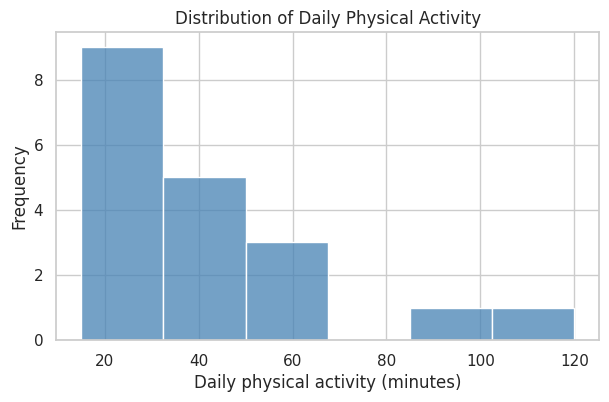

In [9]:
plt.figure(figsize=(7, 4))

sns.histplot(
    x=activity,
    bins=6,
    color="steelblue",
    edgecolor="white",
)

plt.title("Distribution of Daily Physical Activity")
plt.xlabel("Daily physical activity (minutes)")
plt.ylabel("Frequency")

plt.show()

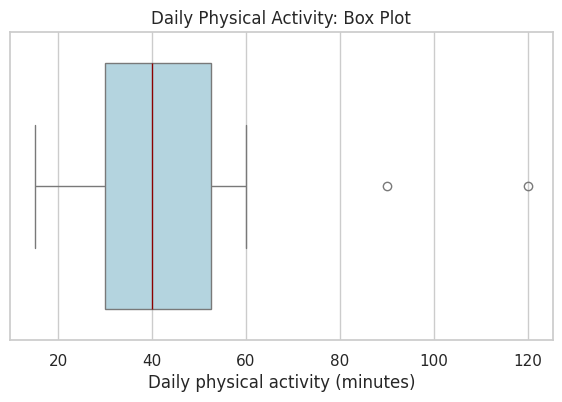

In [10]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    x=activity,
    color="lightblue",
    medianprops={"color": "darkred"},
)

plt.title("Daily Physical Activity: Box Plot")
plt.xlabel("Daily physical activity (minutes)")

plt.show()

#Comment
A box plot normally shows individual markers only for potential outliers

# All variables visualisation

In [4]:
variable_labels = {
    "height_cm": "Height (cm)",
    "weight_kg": "Weight (kg)",
    "activity_minutes": "Daily physical activity (minutes)",
}

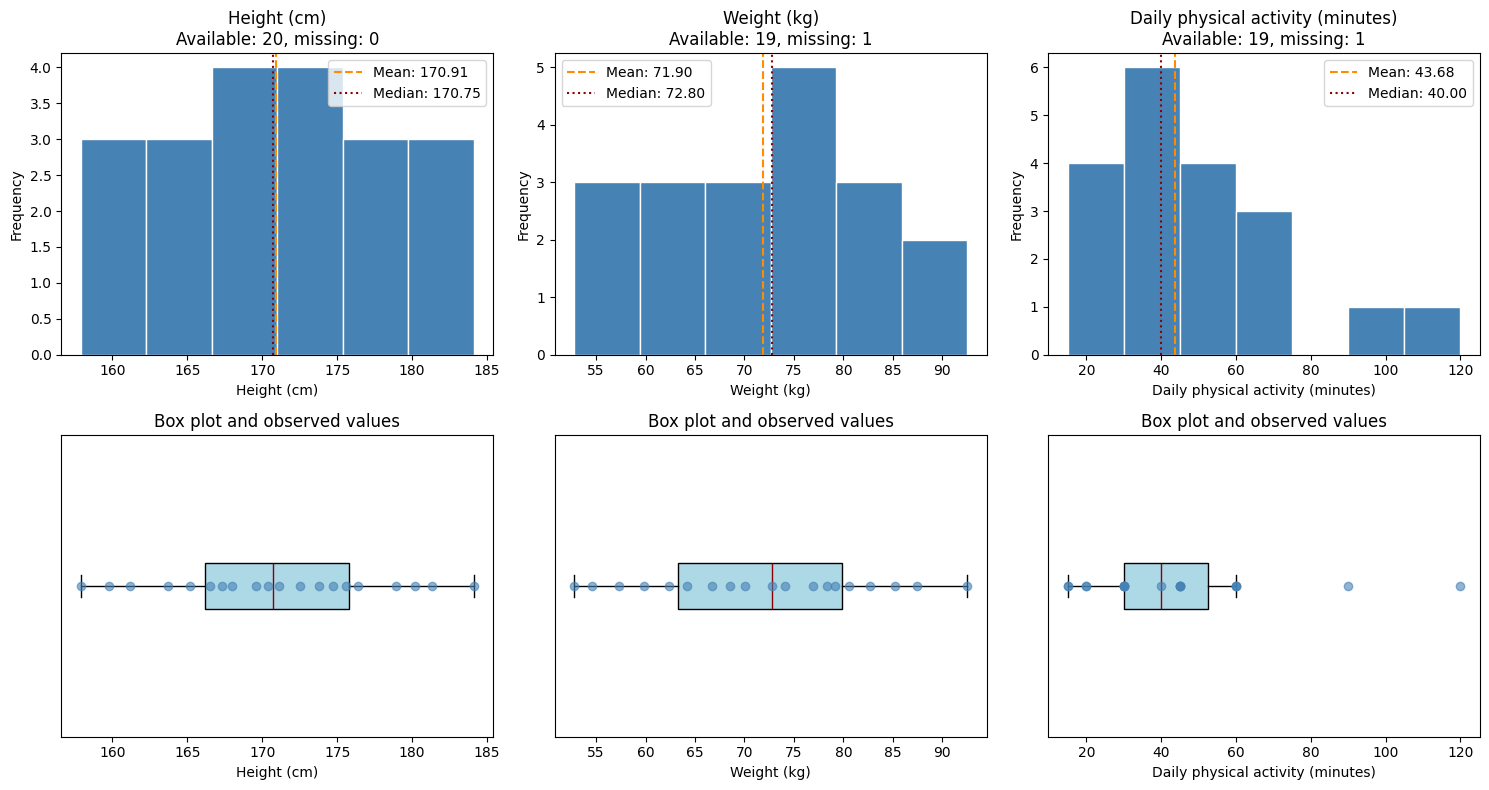

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, (name, label) in enumerate(variable_labels.items()):
    # Exclude missing values for this variable.
    x = df[name].dropna()

    # Histogram with mean and median.
    ax = axes[0, column]

    ax.hist(
        x,
        bins="auto",
        color="steelblue",
        edgecolor="white",
    )

    ax.axvline(
        x.mean(),
        color="darkorange",
        linestyle="--",
        label=f"Mean: {x.mean():.2f}",
    )

    ax.axvline(
        x.median(),
        color="darkred",
        linestyle=":",
        label=f"Median: {x.median():.2f}",
    )

    ax.set_title(f"{label}\nAvailable: {len(x)}, missing: {df[name].isna().sum()}")
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.legend()

    # Box plot with individual observations.
    ax = axes[1, column]

    ax.boxplot(
        x,
        vert=False,
        patch_artist=True,
        showfliers=False,
        boxprops={"facecolor": "lightblue"},
        medianprops={"color": "darkred"},
    )

    # Display every observed value, including potential outliers.
    ax.scatter(
        x,
        [1] * len(x),
        color="steelblue",
        alpha=0.6,
        zorder=3,
    )

    ax.set_xlabel(label)
    ax.set_yticks([])
    ax.set_title("Box plot and observed values")

plt.tight_layout()
plt.show()

## Comments

### Histograms

Histograms show the frequency distribution of each variable.
The vertical lines indicate the mean and median.

A difference between the mean and median can suggest asymmetry.
However, histogram shape depends on the choice of bins,
especially with a small dataset.

### Box Plots

- The box extends from Q1 to Q3.
- The line inside the box marks the median.
- The whiskers extend to the most extreme observations within
  1.5 × IQR of the box.
- Points beyond the whiskers are potential outliers,
  not necessarily errors.

The dots show individual observed values
- `ax.boxplot()` draws the box plot.
- `ax.scatter()` adds all observed values at the same vertical position.

 ***Repeated values may overlap***.

 - `showfliers=False` hides the box plot's own
outlier markers because these observations are already included
in the added points

Missing values are excluded separately for each variable.
The plots describe available observations only.

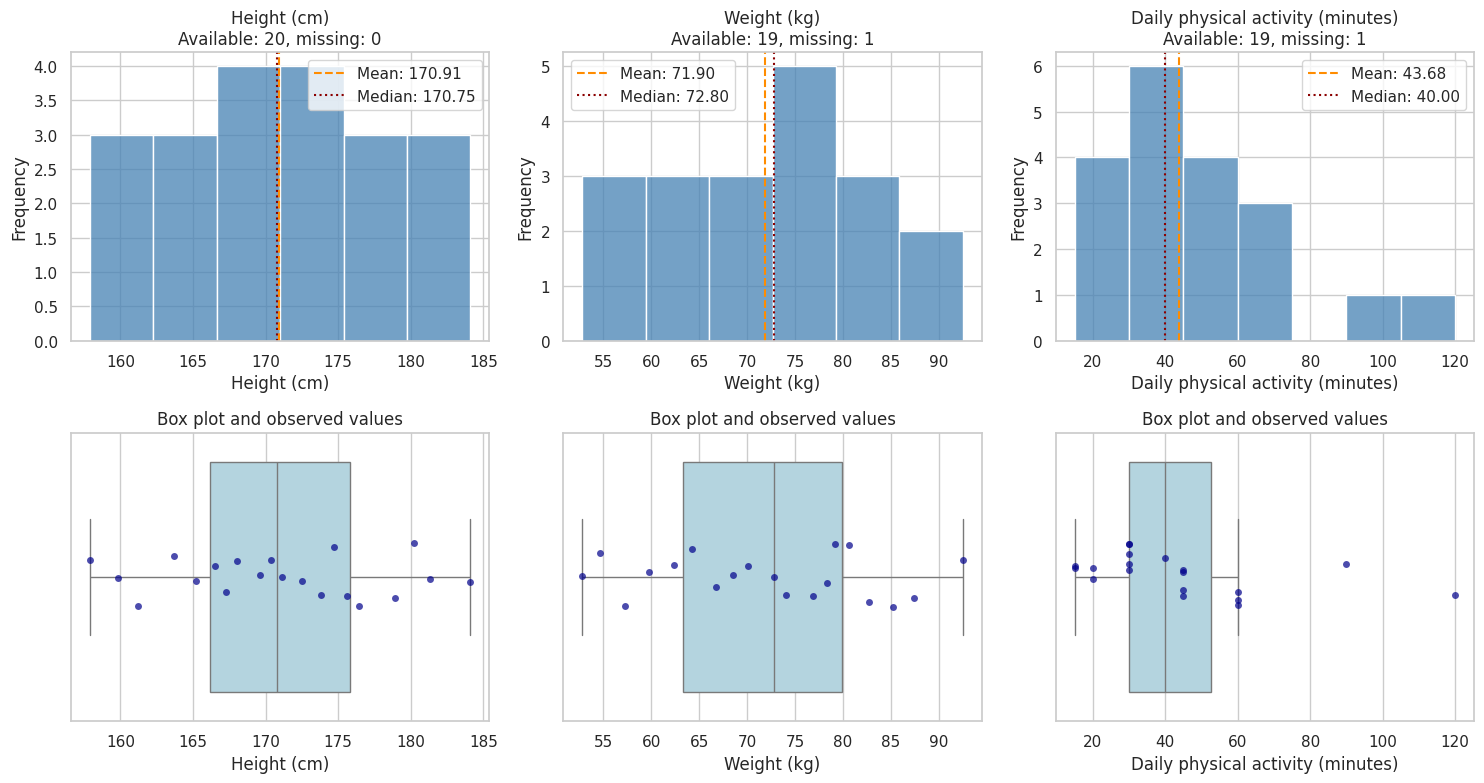

In [5]:
import seaborn as sns


sns.set_theme(style="whitegrid")

variable_labels = {
    "height_cm": "Height (cm)",
    "weight_kg": "Weight (kg)",
    "activity_minutes": "Daily physical activity (minutes)",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for column, (name, label) in enumerate(variable_labels.items()):
    # Exclude missing values for this variable.
    x = df[name].dropna()

    # Histogram.
    ax = axes[0, column]

    sns.histplot(
        x=x,
        bins="auto",
        color="steelblue",
        ax=ax,
    )

    ax.axvline(
        x.mean(),
        color="darkorange",
        linestyle="--",
        label=f"Mean: {x.mean():.2f}",
    )

    ax.axvline(
        x.median(),
        color="darkred",
        linestyle=":",
        label=f"Median: {x.median():.2f}",
    )

    ax.set_title(
        f"{label}\n"
        f"Available: {len(x)}, missing: {df[name].isna().sum()}"
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.legend()

    # Box plot with individual observations.
    ax = axes[1, column]

    sns.boxplot(
        x=x,
        color="lightblue",
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        x=x,
        color="darkblue",
        jitter=0.12,
        alpha=0.7,
        size=5,
        ax=ax,
    )

    ax.set_title("Box plot and observed values")
    ax.set_xlabel(label)

plt.tight_layout()
plt.show()

## Comments
- `sns.boxplot()` draws the box plot.
- `sns.stripplot()` adds all observed values.
- `jitter=0.12` introduces a small random vertical displacement to reduce overlap.
- `showfliers=False` hides the box plot's own
outlier markers because these observations are already included
in the added points